# B / Training-only discovery

Run from the repository root or notebooks/. All core analysis and loading code is included below. No model fitting or holdout EDA. Human review remains pending.

In [1]:
"""Frozen data contract shared by A/B/C/D. No learned transformations."""

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

ROOT = Path.cwd() if (Path.cwd()/"config/dataset_lock.json").exists() else Path.cwd().parent
LOCK = json.loads((ROOT / "config/dataset_lock.json").read_text(encoding="utf-8"))
EXPECTED_COLUMNS = LOCK["columns"]
FEATURES = LOCK["allowed_features"]
EXCLUDED = LOCK["excluded_features"]
NUMERIC = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
CATEGORIES = {
    "job": ["admin.", "unknown", "unemployed", "management", "housemaid", "entrepreneur", "student", "blue-collar", "self-employed", "retired", "technician", "services"],
    "marital": ["married", "divorced", "single"],
    "education": ["unknown", "secondary", "primary", "tertiary"],
    "default": ["yes", "no"], "housing": ["yes", "no"], "loan": ["yes", "no"],
    "contact": ["unknown", "telephone", "cellular"],
    "month": ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"],
    "poutcome": ["unknown", "other", "failure", "success"], "y": ["yes", "no"],
}


def sha256_bytes(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()


def verify_bytes(data: bytes, expected: dict, label: str) -> None:
    if sha256_bytes(data) != expected["sha256"]:
        raise ValueError(f"SHA-256 mismatch: {label}. Do not repair or overwrite the raw file.")
    if "bytes" in expected and len(data) != expected["bytes"]:
        raise ValueError(f"Byte length mismatch: {label}")


def read_raw(root: Path = ROOT) -> pd.DataFrame:
    path = root / "data/raw/bank-full.csv"
    verify_bytes(path.read_bytes(), LOCK["artifacts"]["data/raw/bank-full.csv"], str(path.name))
    raw = pd.read_csv(path, sep=";", keep_default_na=False)
    if list(raw.columns) != EXPECTED_COLUMNS or raw.shape != (45211, 17):
        raise ValueError("Unexpected CSV version, columns, or shape")
    for column in NUMERIC:
        if not pd.api.types.is_integer_dtype(raw[column]):
            raise ValueError(f"Expected integer dtype: {column}")
    for column, allowed in CATEGORIES.items():
        if not raw[column].isin(allowed).all():
            raise ValueError(f"Unexpected category: {column}")
    if raw.isna().any().any() or raw.astype(str).apply(lambda s: s.str.strip().eq("")).any().any():
        raise ValueError("Unexpected actual missing/empty cell")
    raw.index.name = "row_id"  # Original zero-based data-record position, not CSV line number.
    return raw


def make_splits(raw: pd.DataFrame) -> dict[str, np.ndarray]:
    y = raw["y"].map({"no": 0, "yes": 1})
    if y.isna().any():
        raise ValueError("Unexpected target value")
    ids = np.arange(len(raw))
    dev, test = train_test_split(ids, test_size=.20, stratify=y, random_state=42)
    train, val = train_test_split(dev, test_size=.25, stratify=y.iloc[dev], random_state=42)
    return {"train": train, "val": val, "test": test}


def make_manifest(raw: pd.DataFrame, splits: dict[str, np.ndarray]) -> pd.DataFrame:
    assignment = pd.Series("", index=np.arange(len(raw)), name="split")
    for name, ids in splits.items():
        assignment.loc[ids] = name
    result = assignment.rename_axis("row_id").reset_index()
    all_ids = np.concatenate(list(splits.values()))
    if len(all_ids) != len(raw) or len(np.unique(all_ids)) != len(raw):
        raise ValueError("Splits overlap or fail complete coverage")
    if not np.array_equal(np.sort(all_ids), np.arange(len(raw))) or assignment.eq("").any():
        raise ValueError("Invalid split row ids")
    return result


def load_split_indices(root: Path = ROOT) -> dict[str, np.ndarray]:
    saved = json.loads((root / "data/splits/split_indices.json").read_text(encoding="utf-8"))
    if not isinstance(saved, dict) or set(saved) != {"train", "val", "test"}:
        raise ValueError("Unexpected split names")
    for name, ids in saved.items():
        if not isinstance(ids, list) or any(type(value) is not int for value in ids):
            raise ValueError(f"Split {name} row ids must be plain JSON integers; no strings, floats or booleans")
        if any(value < 0 or value >= LOCK["shape"][0] for value in ids):
            raise ValueError(f"Split {name} row id outside original row range")
    return {name: np.asarray(ids, dtype=np.int64) for name, ids in saved.items()}


def validate_saved_splits(raw: pd.DataFrame, root: Path = ROOT) -> dict[str, np.ndarray]:
    expected = make_splits(raw)
    saved = load_split_indices(root)
    for name in expected:
        if not np.array_equal(saved[name], expected[name]):
            raise ValueError(f"Frozen split changed: {name}")
    manifest = pd.read_csv(root / "data/splits/split_manifest.csv", keep_default_na=False)
    pd.testing.assert_frame_equal(manifest, make_manifest(raw, expected))
    return saved


def load_partition(name: str, *, allow_test: bool = False, root: Path = ROOT):
    """Return X (11 original columns), integer y, with aligned row_id indices.

    The flag is a workflow guard, not access control: raw data remain available.
    C/D must preserve this row order and fit learned transforms only on training.
    """
    if name not in {"train", "val", "test"}:
        raise ValueError("Expected train, val, or test")
    if name == "test" and not allow_test:
        raise ValueError("Test is sealed until protocol freeze; D must explicitly allow_test=True")
    raw = read_raw(root)
    splits = validate_saved_splits(raw, root)
    frame = raw.loc[splits[name]]
    X = frame.loc[:, FEATURES].copy()
    y = frame["y"].map({"no": 0, "yes": 1}).astype("int64")
    if not X.index.equals(y.index) or list(X.columns) != FEATURES:
        raise ValueError("Broken model-input contract")
    return X, y


In [2]:
"""B: descriptive investigation restricted to A's frozen training partition."""
from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt




def summarize(frame, keys):
    result = frame.groupby(keys, observed=True, dropna=False)['target'].agg(
        n='size', n_positive='sum').reset_index()
    result['n_negative'] = result.n - result.n_positive
    result['subscription_rate'] = result.n_positive / result.n
    result['small_sample'] = (result.n < 100) | (result.n_positive < 20) | (result.n_negative < 20)
    result['partition'] = 'train'
    return result


def investigate():
    X, y = load_partition('train')
    f = X.copy()
    f['target'] = y
    f['age_group'] = np.where(f.age < 30, '<30', np.where(f.age < 60, '30-59', '>=60'))
    f['history_group'] = np.where(f.pdays < 0, 'never_contacted', 'previously_contacted')
    f['previous_group'] = np.where(f.previous == 0, 'zero', 'positive')
    history = summarize(f, ['history_group', 'previous_group', 'poutcome'])
    history['share_of_train'] = history.n / len(f)
    exceptional = f.loc[(f.pdays.ge(0) & f.poutcome.eq('unknown')) |
                        (f.pdays.ge(0) != f.previous.gt(0))].copy()
    exceptional['reason'] = np.where(exceptional.pdays.ge(0) != exceptional.previous.gt(0),
        'pdays_previous_disagreement', 'contact_recorded_outcome_unknown')
    exceptional['interpretation'] = 'Observed combination; original cause is not identifiable; retain unchanged'

    overview = []
    for label, mask in [('target_yes', y.eq(1)), ('job_unknown', f.job.eq('unknown')),
                        ('education_unknown', f.education.eq('unknown')),
                        ('any_unknown', f.job.eq('unknown') | f.education.eq('unknown')),
                        ('pdays_minus_one', f.pdays.eq(-1)), ('pdays_nonnegative', f.pdays.ge(0))]:
        overview.append(dict(measure=label, n=int(mask.sum()), denominator=len(f),
                             proportion=float(mask.mean()), n_positive=int(y[mask].sum()), partition='train'))
    unknown_tables = []
    for field in ['job', 'education', 'any_unknown']:
        mask = (f.job.eq('unknown') | f.education.eq('unknown')) if field == 'any_unknown' else f[field].eq('unknown')
        for dimension in ['overall', 'age_group', 'history_group']:
            g = f[['target', 'age_group', 'history_group']].copy()
            g['stratum'] = 'all' if dimension == 'overall' else g[dimension]
            g['information'] = np.where(mask, 'unknown', 'known')
            table = summarize(g, ['stratum', 'information'])
            table['field'] = field
            table['dimension'] = dimension
            table['stratum_n'] = table.groupby('stratum').n.transform('sum')
            table['share_in_stratum'] = table.n / table.stratum_n
            unknown_tables.append(table)
    unknown = pd.concat(unknown_tables, ignore_index=True)
    differences = []
    for (field, dimension, stratum), group in unknown.groupby(['field', 'dimension', 'stratum'], sort=False):
        indexed = group.set_index('information')
        if {'unknown', 'known'} <= set(indexed.index):
            differences.append(dict(field=field, dimension=dimension, stratum=stratum,
                unknown_minus_known_pp=100*(indexed.loc['unknown', 'subscription_rate']-indexed.loc['known', 'subscription_rate']),
                unknown_n=int(indexed.loc['unknown','n']), known_n=int(indexed.loc['known','n']),
                small_sample=bool(indexed.small_sample.any()), partition='train'))

    # Direct standardization describes age composition; it is not causal adjustment.
    weights = f.age_group.value_counts(normalize=True)
    standardized = []
    for field in ['job', 'education', 'any_unknown']:
        part = unknown[(unknown.field == field) & (unknown.dimension == 'age_group')]
        for info in ['known', 'unknown']:
            rates = part[part.information == info].set_index('stratum').subscription_rate.reindex(weights.index)
            standardized.append(dict(field=field, information=info,
                age_standardized_rate=float((rates*weights).sum()) if rates.notna().all() else np.nan,
                weights='pooled training age distribution', partition='train'))

    quality, tails = [], []
    for field in ['balance', 'previous']:
        s = f[field]
        quality.append(dict(field=field, n=len(s), negative_n=int(s.lt(0).sum()), zero_n=int(s.eq(0).sum()),
            minimum=int(s.min()), q01=float(s.quantile(.01)), q25=float(s.quantile(.25)),
            median=float(s.median()), q75=float(s.quantile(.75)), q95=float(s.quantile(.95)),
            q99=float(s.quantile(.99)), maximum=int(s.max()), partition='train'))
        selected = pd.concat([f.nsmallest(5, field), f.nlargest(5, field)]).drop_duplicates()
        selected = selected.reset_index()[['row_id', 'age', 'balance', 'previous', 'pdays', 'poutcome', 'target']]
        selected['selected_by'] = field + '_five_lowest_and_highest'
        selected['partition'] = 'train'
        tails.append(selected)
    assert history.n.sum() == len(f)
    assert history.n_positive.sum() == int(y.sum())
    assert all(t.n.sum() == len(f) for _, t in unknown.groupby(['field','dimension']))
    return {'overview': pd.DataFrame(overview), 'history_crosstab': history,
            'history_exceptions': exceptional.reset_index(), 'unknown_strata': unknown,
            'unknown_differences': pd.DataFrame(differences), 'age_standardized': pd.DataFrame(standardized),
            'numeric_quality': pd.DataFrame(quality), 'numeric_tail_examples': pd.concat(tails, ignore_index=True),
            'training_row_ids': pd.DataFrame({'row_id': X.index}),
            'age_weights': weights.rename_axis('age_group').rename('weight').reset_index()}


def draw_figures(tables, folder):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update({'font.size': 10, 'figure.dpi': 140})
    overview = tables['overview']
    fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
    ax.barh(overview.measure, overview.proportion*100, color='#28758b')
    for i, row in overview.iterrows():
        ax.text(row.proportion*100+.5, i, f'{row.n:,}/{row.denominator:,} ({row.proportion:.1%})', va='center', fontsize=9)
    ax.set(xlim=(0,115), xlabel='Percent of fixed training partition', title='Special states are different kinds of information (train only)')
    fig.savefig(folder/'01_overview.png'); plt.close(fig)

    h = tables['history_crosstab']
    fig, ax = plt.subplots(figsize=(10, 4.8), layout='constrained')
    labels = h.history_group + ' / ' + h.previous_group + ' / ' + h.poutcome
    ax.barh(labels, h.n, color='#28758b')
    ax.set_xscale('log')
    for i, row in h.iterrows():
        ax.text(row.n*1.12, i, f'n={row.n:,}; yes={row.n_positive:,}', va='center', fontsize=9)
    ax.set(xlim=(1,1000000), xlabel='Record count (log scale); training n=27,126',
           title='History status overlaps across fields; five contacted records still have unknown outcome')
    fig.savefig(folder/'02_history.png'); plt.close(fig)

    u = tables['unknown_strata']
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
    ages = ['<30','30-59','>=60']
    age = u[u.dimension.eq('age_group')]
    for field, offset, color in [('job',-.24,'#28758b'),('education',0,'#bd8831'),('any_unknown',.24,'#785e9c')]:
        part = age[age.field.eq(field) & age.information.eq('unknown')].set_index('stratum').reindex(ages)
        axes[0].bar(np.arange(3)+offset, part.share_in_stratum*100, width=.23, label=field, color=color)
    denominators = age[age.field.eq('any_unknown') & age.information.eq('unknown')].set_index('stratum').stratum_n
    age_labels = [f'{label}\nn={int(denominators[label]):,}' for label in ages]
    axes[0].set(xticks=np.arange(3), xticklabels=age_labels, ylabel='Unknown / age-stratum n (%)', title='Information completeness varies with age')
    axes[0].legend(fontsize=8)
    for info, offset, color in [('known',-.19,'#28758b'),('unknown',.19,'#bd8831')]:
        part = age[age.field.eq('any_unknown') & age.information.eq(info)].set_index('stratum').reindex(ages)
        axes[1].bar(np.arange(3)+offset, part.subscription_rate*100, width=.36, label=info, color=color)
        for i, (_, row) in enumerate(part.iterrows()):
            axes[1].text(i+offset,row.subscription_rate*100+.7,f'{int(row.n_positive)}/{int(row.n)}'+('*' if row.small_sample else ''),
                         ha='center', fontsize=8, rotation=20)
    axes[1].set(xticks=np.arange(3), xticklabels=ages, ylim=(0,44), ylabel='Yes / information-group n (%)', title='Overall unknown association is not uniform by age')
    axes[1].legend(fontsize=8)
    fig.supxlabel('Train only; * small sample (n<100 or either outcome count<20). Descriptive, not causal.')
    fig.savefig(folder/'03_unknown_age.png'); plt.close(fig)


def write_outputs(root=ROOT):
    tables = investigate()
    out = Path(root)/'outputs/B'
    out.mkdir(parents=True, exist_ok=True)
    for name, table in tables.items():
        table.to_csv(out/f'{name}.csv', index=False)
    draw_figures(tables, out/'figures')
    report = {'partition': 'train', 'n': len(tables['training_row_ids']),
        'n_positive': int(tables['history_crosstab'].n_positive.sum()),
        'exploratory_holdout_access': False, 'human_review': 'pending',
        'environment': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__},
        'inputs_sha256': {p:hashlib.sha256((Path(root)/p).read_bytes()).hexdigest() for p in
             ['data/raw/bank-full.csv','data/splits/split_indices.json','data/splits/split_manifest.csv']}}
    (out/'run_manifest.json').write_text(json.dumps(report, indent=2)+'\n', encoding='utf-8')
    return tables




In [3]:
tables = investigate()
from IPython.display import display
for name, table in tables.items():
    if name != "training_row_ids":
        print(name)
        display(table)

overview


,measure,n,denominator,proportion,n_positive,partition
0,target_yes,3173,27126,0.116973,3173,train
1,job_unknown,179,27126,0.006599,22,train
2,education_unknown,1100,27126,0.040552,152,train
3,any_unknown,1206,27126,0.044459,163,train
4,pdays_minus_one,22235,27126,0.819693,2058,train
5,pdays_nonnegative,4891,27126,0.180307,1115,train


history_crosstab


,history_group,previous_group,poutcome,n,n_positive,n_negative,subscription_rate,small_sample,partition,share_of_train
0,never_contacted,zero,unknown,22235,2058,20177,0.092557,False,train,0.819693
1,previously_contacted,positive,failure,2876,359,2517,0.124826,False,train,0.106024
2,previously_contacted,positive,other,1117,184,933,0.164727,False,train,0.041178
3,previously_contacted,positive,success,893,570,323,0.638298,False,train,0.032920
4,previously_contacted,positive,unknown,5,2,3,0.400000,True,train,0.000184


history_exceptions


...

,field,n,negative_n,zero_n,minimum,q01,q25,median,q75,q95,q99,maximum,partition
0,balance,27126,2280,2089,-6847,-627.0,73.0,454.0,1425.75,5768.75,13146.25,81204,train
1,previous,27126,0,22235,0,0.0,0.0,0.0,0.00,3.00,9.00,58,train


numeric_tail_examples


,row_id,age,balance,previous,pdays,poutcome,target,selected_by,partition
0,15682,49,-6847,0,-1,unknown,0,balance_five_lowest_and_highest,train
1,38736,60,-4057,0,-1,unknown,0,balance_five_lowest_and_highest,train
2,7413,43,-3372,0,-1,unknown,0,balance_five_lowest_and_highest,train
3,1896,57,-3313,0,-1,unknown,0,balance_five_lowest_and_highest,train
4,18573,40,-2827,0,-1,unknown,0,balance_five_lowest_and_highest,train
5,43393,84,81204,3,94,success,1,balance_five_lowest_and_highest,train
6,42558,84,81204,2,313,other,1,balance_five_lowest_and_highest,train
7,41693,60,71188,0,-1,unknown,0,balance_five_lowest_and_highest,train
8,19785,56,66721,0,-1,unknown,0,balance_five_lowest_and_highest,train
9,21192,52,66653,0,-1,unknown,0,balance_five_lowest_and_highest,train


age_weights


,age_group,weight
0,30-59,0.842292
1,<30,0.117784
2,>=60,0.039925


# B / D2：数据洞察与处理依据

本报告仅探索固定训练集：27,126 条，3,173 个正例。代码：`src/b_discovery.py`；原始表：`outputs/B/`。比例均注明分母，不对验证或测试数据做开放式 EDA。分析由 OpenAI Codex 按用户指令辅助完成；B 本人的实际理解与复核待记录。

## 核心发现：未知值的语义必须由跨字段关系解释

训练集中 `pdays>=0` 与 `previous>0` 的状态完全对应；但 `poutcome=unknown` 有两种观察情境：22,235 条无联系历史，另有 5 条已联系历史。后者占所有 outcome unknown 的 5/22240（0.0225%）。

| history_group | previous_group | poutcome | n | n_positive | subscription_rate |
| --- | --- | --- | --- | --- | --- |
| never_contacted | zero | unknown | 22235 | 2058 | 0.0925568 |
| previously_contacted | positive | failure | 2876 | 359 | 0.124826 |
| previously_contacted | positive | other | 1117 | 184 | 0.164727 |
| previously_contacted | positive | success | 893 | 570 | 0.638298 |
| previously_contacted | positive | unknown | 5 | 2 | 0.4 |

单看 unknown 计数，无法区分“没有前次活动可记录”与“有前次活动但结果未知”；后者的真实原因无法从公开字段识别，不能自动归为解析错误。例外 row_id 和原值见 `history_exceptions.csv`，全部保留。

这支持 S 明确区分联系状态与间隔、U 仅作用于 job/education，而不统一填补 poutcome。与此同时，previous 的零/正状态已能表达相同联系状态，poutcome 也高度重叠，因此 S 的额外预测收益可能有限。不过 previous 作为连续数值进入逻辑回归并不等价于二元状态，不能证明 S 数学上冗余。S 还改变维数和正则化几何，模型对比不是纯因果效应。

## 辅助发现一：unknown 的总体关联在年龄组中不一致

| dimension | stratum | information | n | n_positive | subscription_rate | small_sample |
| --- | --- | --- | --- | --- | --- | --- |
| overall | all | known | 25920 | 3010 | 0.116127 | False |
| overall | all | unknown | 1206 | 163 | 0.135158 | False |
| age_group | 30-59 | known | 21856 | 2154 | 0.0985542 | False |
| age_group | 30-59 | unknown | 992 | 106 | 0.106855 | False |
| age_group | <30 | known | 3078 | 524 | 0.17024 | False |
| age_group | <30 | unknown | 117 | 29 | 0.247863 | False |
| age_group | >=60 | known | 986 | 332 | 0.336714 | False |
| age_group | >=60 | unknown | 97 | 28 | 0.28866 | True |

总体未知组认购率 13.52%，两列已知组 11.61%；年轻组未知状态对应更高认购率，≥60 岁组则方向不同。≥60 未知组仅 97 条，因此必须标注小样本。并非所有分层方向与总体相反，不称为辛普森悖论。原始 job、education 的独立分层，以及联系历史分层均见 `unknown_strata.csv`；该表还报告 unknown/所在分层样本数。

替代解释包括客户构成、记录流程差异、未测量因素和随机波动。未知信息不必然随机出现，但本结果也不能判定缺失机制为 MAR/MNAR。众数填补会合并可观察的信息状态，保留类别可能保留有用信息，也可能加剧小样本估计波动。因此 U 应用相同模型实测，而不能预先承诺提升或公平性改善。

### 年龄构成的描述性检查

以下按同一训练集年龄权重重加权各年龄组认购率；不拟合模型、不改变分组、不做因果调整。

| field | information | age_standardized_rate | weights | partition |
| --- | --- | --- | --- | --- |
| job | known | 0.116995 | pooled training age distribution | train |
| job | unknown | 0.132869 | pooled training age distribution | train |
| education | known | 0.116425 | pooled training age distribution | train |
| education | unknown | 0.132485 | pooled training age distribution | train |
| any_unknown | known | 0.116506 | pooled training age distribution | train |
| any_unknown | unknown | 0.130722 | pooled training age distribution | train |

权重见 `age_weights.csv`。标准化只控制这里的粗年龄构成，不能排除年龄组内差异或其他混杂；97 条样本的波动仍保留。

对任一 unknown 的信息组，粗认购率差为 +1.9031 个百分点；使用共同年龄构成后为 +1.4216 个百分点。两者差异显示年龄构成会影响总体比较，但不把剩余差值解释成 unknown 的因果作用。该重加权仅作为训练集解释证据，不改变模型训练数据或 D 的评价分组。

## 辅助发现二：数值尾部需要治理，不能默认删除

| field | n | negative_n | zero_n | minimum | q01 | q25 | median | q75 | q95 | q99 | maximum | partition |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| balance | 27126 | 2280 | 2089 | -6847 | -627 | 73 | 454 | 1425.75 | 5768.75 | 13146.2 | 81204 | train |
| previous | 27126 | 0 | 22235 | 0 | 0 | 0 | 0 | 0 | 3 | 9 | 58 | train |

`numeric_tail_examples.csv` 保存余额与历史联系次数的极端训练记录及 row_id。负余额在字段语义上可允许，高联系次数值得核查但缺少逐次历史，不能证明错误，也不能确认每个极端值真实有效。本研究保留全部行；所有实验使用同样的 StandardScaler，未引入删行、截尾、log 变换或额外异常值因素。线性模型仍可能受长尾影响，这是本研究范围限制。

## 从观察到实验

| 观察 | 准备决策 | 验证方式 | 解释边界 |
| --- | --- | --- | --- |
| 哨兵状态与间隔不同，其他历史字段已高度重叠 | S 拆分状态与条件间隔 | ES−E0、ESU−EU | 小收益不代表语义无价值，也不证明完全冗余 |
| job/education unknown 的关联随分层变化 | U 保留类别 vs 训练众数 | EU−E0、ESU−ES | 不能因关联而推断因果或缺失机制 |
| 总体平均可能掩盖群体差异 | 固定年龄及原始信息完整性组 | Recall、FPR、Brier 与分母 | 分组差异不等于歧视判定 |

验证/最终测试结果与解释另见 `notes/RESULTS.md`，避免把测试结果混入训练集发现。所有改进、恶化和无变化均报告。没有置信区间或显著性检验，不使用“显著改善”。无客户 ID 和精确快照时间，不能保证客户级独立性、未来泛化或营销因果收益。

## 图与交接

三张训练主图：`01_overview.png`、`02_history.png`、`03_unknown_age.png`；第四张由 D 结果生成 `04_model_tradeoffs.png`，与训练图明确区分。每张图的原表随包提供。

C：将本章放入最终 Notebook 的 EDA 章节，沿用 S/U 实现。D：沿用 `notes/B_groups_review.md` 的固定分组，将模型变化与上述可能解释对应。全组：人工核查 5 条例外、主要表分母和结果解释；不要把 AI 自动化验证写成人工签字。


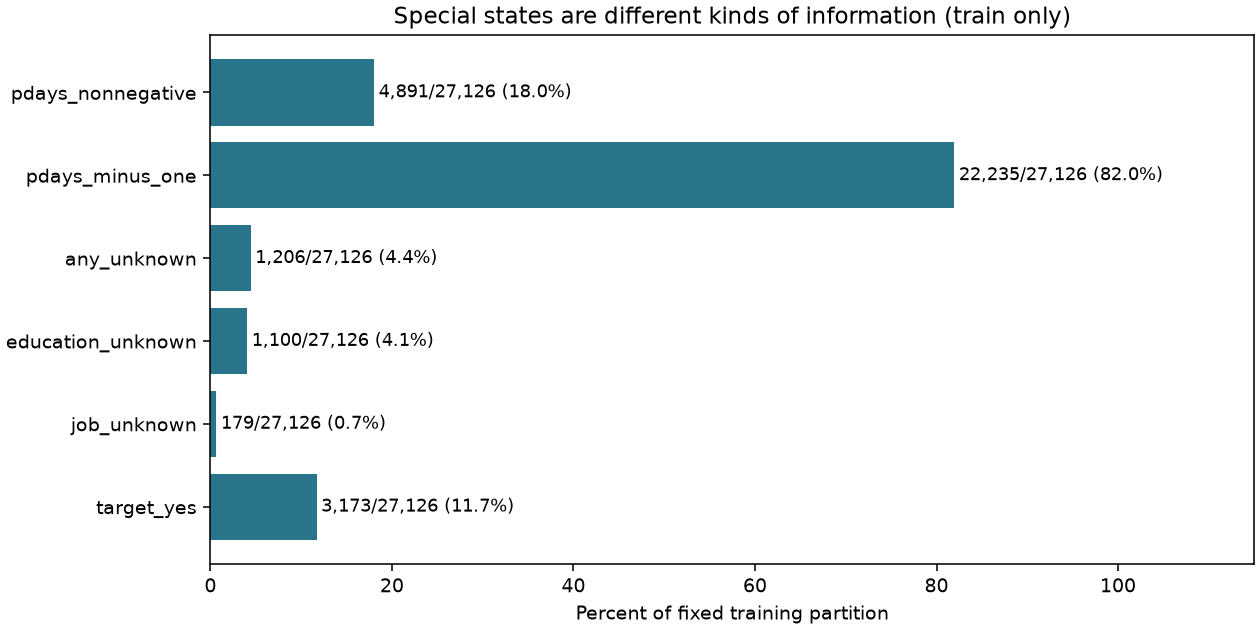

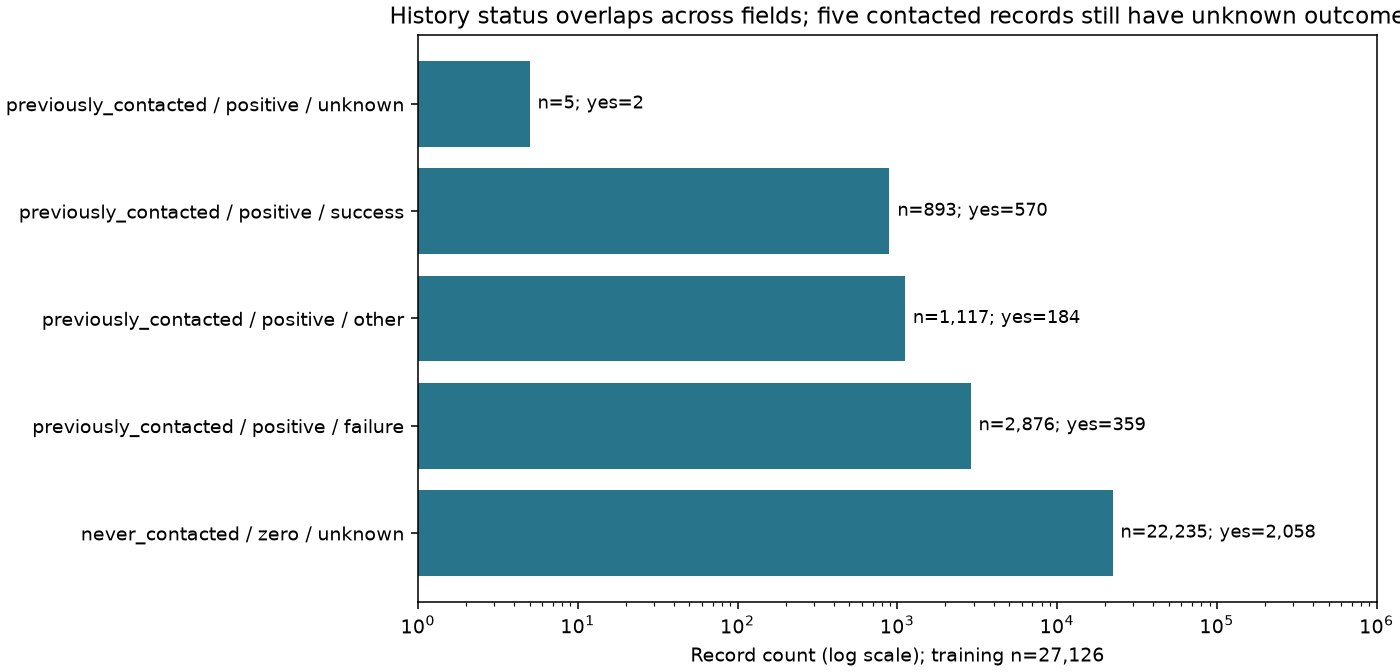

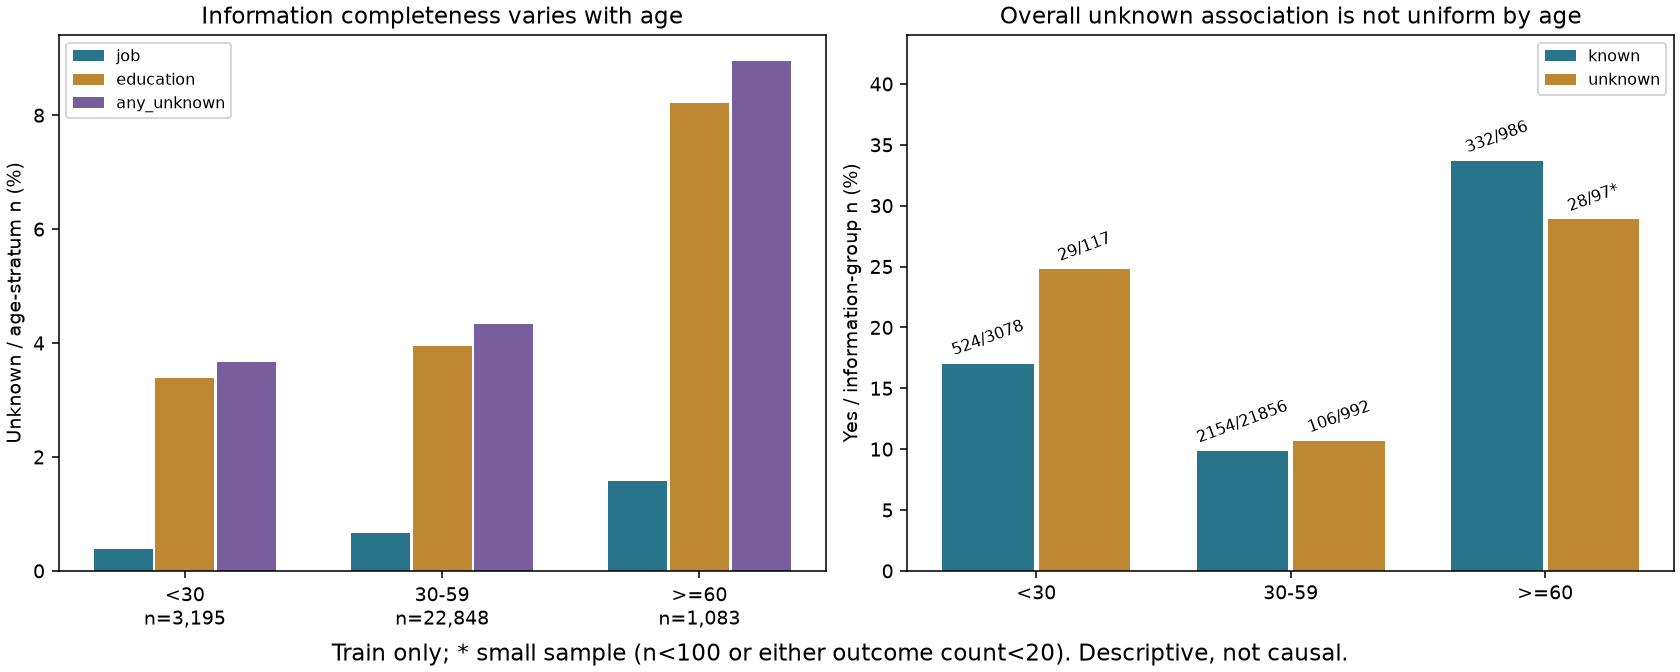

In [4]:
import tempfile
from IPython.display import Image, display
with tempfile.TemporaryDirectory() as folder:
    draw_figures(tables, folder)
    for path in sorted(Path(folder).glob("*.png")):
        display(Image(filename=str(path)))

## GenAI disclosure
OpenAI Codex assisted code, analysis, charts, narrative, and automated validation. Independent CSV reconstruction and frozen row alignment checks are in scripts/validate_b.py. Members must understand and personally verify the work; no human signature is implied.